<a href="https://colab.research.google.com/github/oloyededavid/observational-hydrology-extremes/blob/main/waves_niger_benue_hydrodynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install geemap if not already in your Colab environment
!pip install geemap -q

import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# Authenticate and Initialize the Earth Engine Python API
ee.Authenticate()
ee.Initialize(project='citric-abbey-380805') # Replace with your active GEE project ID

In [ ]:
import ee

# 1. Define the Ungauged Catchment: Lower Niger-Benue Confluence (Lokoja to Ogbaru)
catchment_roi = ee.Geometry.BBox(6.50, 5.80, 7.30, 8.00)

# 2. SAR Processing Function
def get_s1_backscatter(start_date, end_date):
    """
    Pulls Sentinel-1 Interferometric Wide (IW) swath data,
    VH polarization (highly sensitive to surface water),
    and applies a spatial focal median to reduce radar speckle.
    """
    s1_collection = (ee.ImageCollection('COPERNICUS/S1_GRD')
        .filterBounds(catchment_roi)
        .filterDate(start_date, end_date)
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
        .filter(ee.Filter.eq('instrumentMode', 'IW'))
        .select('VH'))

    # Calculate median backscatter for the period to eliminate temporal noise
    median_sar = s1_collection.median()

    # Apply a 3x3 low-pass speckle filter
    return median_sar.focal_median(1.5, 'circle', 'pixels').clip(catchment_roi)

# 3. Extract the Hydrological Extremes (2022 Flood Cycle)
# Baseline: Dry Season (Jan - Mar)
sar_baseline_dry = get_s1_backscatter('2022-01-01', '2022-03-31')

# Extreme: Peak Monsoon Pulse (Sep - Nov)
sar_peak_flood = get_s1_backscatter('2022-09-01', '2022-11-30')

print("Sentinel-1 SAR physical arrays successfully processed in the cloud.")

Sentinel-1 SAR physical arrays successfully processed in the cloud.


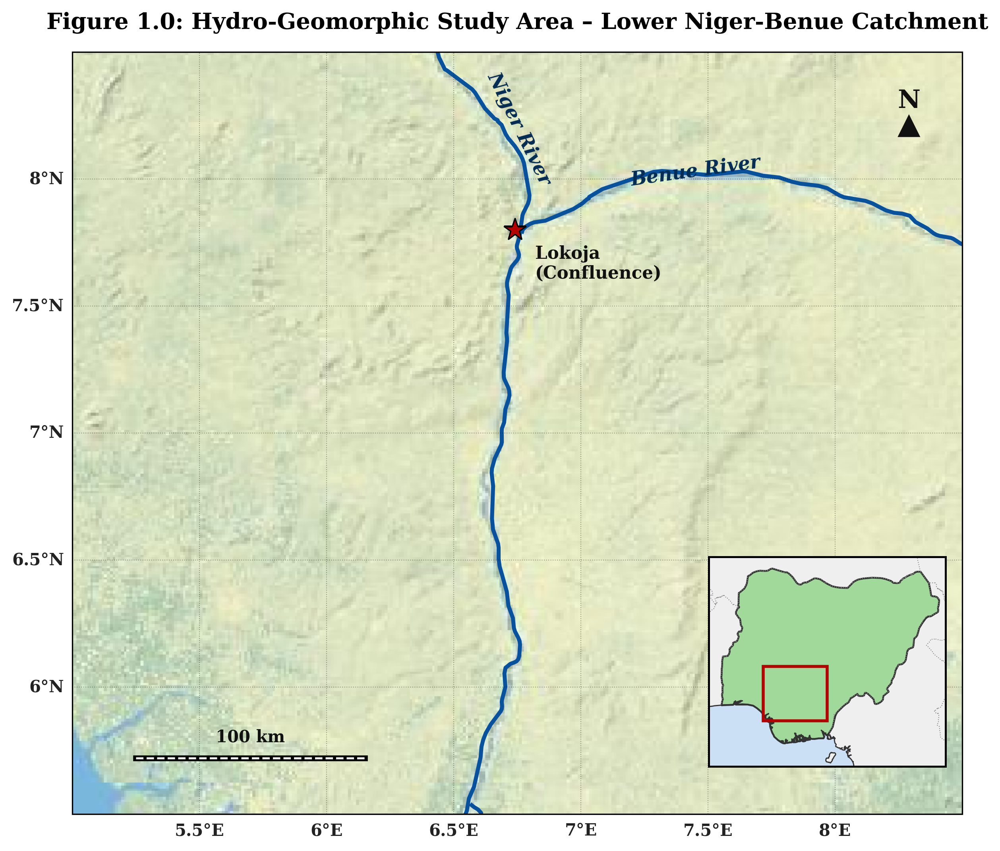

<Figure size 640x480 with 0 Axes>

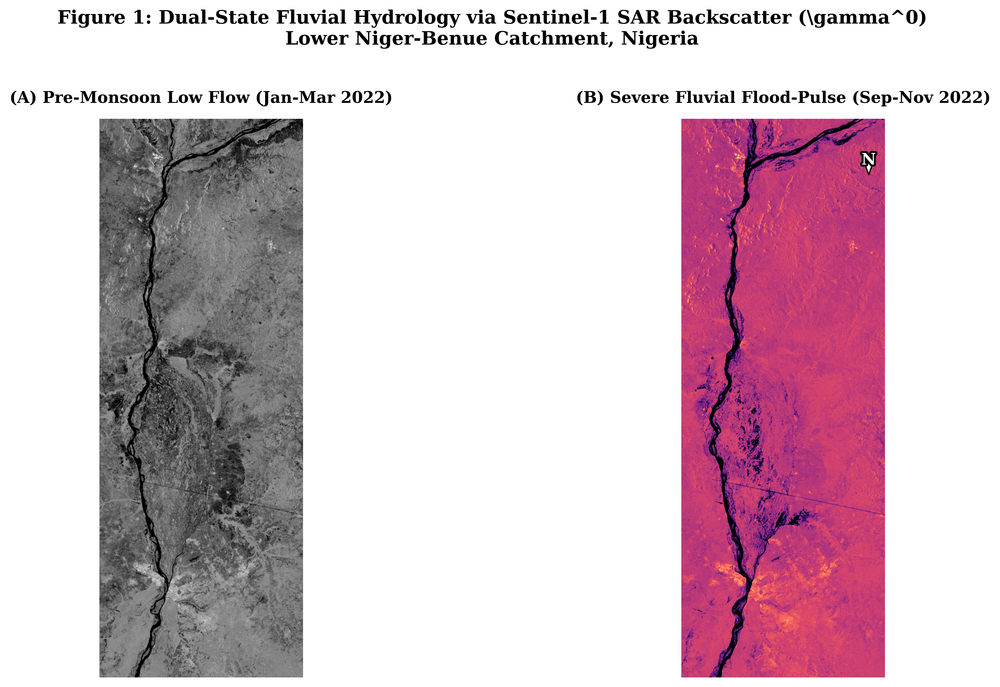

Figure 1 generated and saved: waves_figure1_sar_hydrodynamics.png


In [ ]:
!pip install cartopy -q

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.patches as mpatches
import cartopy.io.img_tiles as cimgt
import cartopy.io.shapereader as shpreader
import geemap

# 1. Cartographic Styling (Serif typography)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

# 2. Spatial Extents
main_extent = [5.0, 8.5, 5.5, 8.5]
inset_extent = [2.0, 15.0, 3.0, 14.5]

fig = plt.figure(figsize=(10, 8), dpi=300)
ax_main = fig.add_axes([0.1, 0.1, 0.8, 0.8], projection=ccrs.PlateCarree())
ax_inset = fig.add_axes([0.65, 0.15, 0.22, 0.22], projection=ccrs.PlateCarree())

# --- 3. Build Main Map ---
ax_main.set_extent(main_extent, crs=ccrs.PlateCarree())

# ESRI Physical basemap
esri_physical = cimgt.GoogleTiles(url='https://server.arcgisonline.com/ArcGIS/rest/services/World_Physical_Map/MapServer/tile/{z}/{y}/{x}')
ax_main.add_image(esri_physical, 7)

# High-resolution river centerline vectors
rivers_10m = cfeature.NaturalEarthFeature('physical', 'rivers_lake_centerlines', '10m',
                                          edgecolor='#08519c', facecolor='none', linewidth=2.4)
ax_main.add_feature(rivers_10m)

# Graticules
gl = ax_main.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                       linewidth=0.5, color='black', alpha=0.35, linestyle=':')
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'size': 10, 'weight': 'bold', 'color': '#222222'}
gl.ylabel_style = {'size': 10, 'weight': 'bold', 'color': '#222222'}

# --- 4. River Annotations (Matched to hand-drawn boxes) ---
# Niger River: Moved to the right (East) bank, aligned to flow
ax_main.text(6.62, 8.20, 'Niger River', transform=ccrs.PlateCarree(),
             fontsize=11.5, color='#042c54', fontstyle='italic', rotation=-64,
             fontweight='bold', ha='left', va='center')

# Benue River: Moved to the top (North) bank, sitting above the channel
ax_main.text(7.45, 7.96, 'Benue River', transform=ccrs.PlateCarree(),
             fontsize=11.5, color='#042c54', fontstyle='italic', rotation=8,
             fontweight='bold', ha='center', va='bottom')

# Lokoja Confluence Marker
ax_main.plot(6.74, 7.80, marker='*', color='#b30000', markersize=14,
             transform=ccrs.PlateCarree(), markeredgecolor='black', markeredgewidth=0.8, zorder=6)
ax_main.text(6.82, 7.74, 'Lokoja\n(Confluence)', transform=ccrs.PlateCarree(),
             fontsize=10.5, fontweight='bold', va='top', ha='left', color='#111111')

# --- 5. Scale Bar & North Arrow ---
# North Arrow
x_n, y_n = 0.94, 0.92
ax_main.annotate('N', xy=(x_n, y_n), xycoords='axes fraction', ha='center', va='bottom',
                 fontsize=15, fontweight='bold', color='#111111')
ax_main.annotate('▲', xy=(x_n, y_n - 0.035), xycoords='axes fraction', ha='center', va='bottom',
                 fontsize=18, color='#111111')

# Scale Bar (~100 km)
bar_lon_start, bar_lat = 5.25, 5.72
bar_lon_end = bar_lon_start + 0.90
ax_main.plot([bar_lon_start, bar_lon_end], [bar_lat, bar_lat], color='black', linewidth=3.5, transform=ccrs.PlateCarree())
ax_main.plot([bar_lon_start, bar_lon_end], [bar_lat, bar_lat], color='white', linewidth=1.2, linestyle='--', transform=ccrs.PlateCarree())
ax_main.text((bar_lon_start + bar_lon_end) / 2, bar_lat + 0.05, '100 km', transform=ccrs.PlateCarree(),
             ha='center', va='bottom', fontweight='bold', fontsize=10, color='#111111')

ax_main.set_title('Figure 1.0: Hydro-Geomorphic Study Area – Lower Niger-Benue Catchment',
                  fontsize=13.5, fontweight='bold', pad=14)

# --- 6. Inset Map (Nigeria Administrative Polygon) ---
ax_inset.set_extent(inset_extent, crs=ccrs.PlateCarree())
ax_inset.add_feature(cfeature.LAND, facecolor='#efefef', edgecolor='none')
ax_inset.add_feature(cfeature.OCEAN, facecolor='#cce0f5')

shpfilename = shpreader.natural_earth(resolution='50m', category='cultural', name='admin_0_countries')
reader = shpreader.Reader(shpfilename)
nigeria_geom = [country.geometry for country in reader.records() if country.attributes['ADMIN'] == 'Nigeria']

ax_inset.add_geometries(nigeria_geom, ccrs.PlateCarree(), facecolor='#a1d99b', edgecolor='#333333', linewidth=1.1)
ax_inset.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='#888888', linestyle=':')
ax_inset.add_feature(cfeature.COASTLINE, linewidth=0.7, edgecolor='#333333')

# Study area extent boundary on inset
rect = mpatches.Rectangle((main_extent[0], main_extent[2]),
                          main_extent[1] - main_extent[0],
                          main_extent[3] - main_extent[2],
                          linewidth=1.8, edgecolor='#b30000', facecolor='none',
                          transform=ccrs.PlateCarree(), zorder=5)
ax_inset.add_patch(rect)

for spine in ax_inset.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)

# Save figure
plt.savefig("waves_fig1_0_study_area_final.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.suptitle(r'Figure 1: Dual-State Fluvial Hydrology via Sentinel-1 SAR Backscatter (\gamma^0)' + '\nLower Niger-Benue Catchment, Nigeria', fontsize=14, fontweight='bold', y=1.02)# Prepare the cartographic engine
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=300)

# Define radar visualization parameters (-25 dB is black/smooth water, -5 dB is white/rough land)
vis_params = {'min': -25, 'max': -5, 'palette': ['#000000', '#4a4a4a', '#a3a3a3', '#ffffff']}

# --- Panel A: Baseline Dry Season ---
# We use geemap.ee_to_matplotlib to fetch the cloud array for the plot
img_dry = geemap.ee_to_numpy(sar_baseline_dry, region=catchment_roi, scale=100) # 100m scale for fast rendering
ax1.imshow(img_dry, cmap='gray', vmin=-25, vmax=-5)
ax1.set_title('(A) Pre-Monsoon Low Flow (Jan-Mar 2022)', fontsize=12, fontweight='bold', pad=12)
ax1.axis('off')

# --- Panel B: Peak Flood Pulse ---
img_flood = geemap.ee_to_numpy(sar_peak_flood, region=catchment_roi, scale=100)
# Using a magma-like colormap base, but inverted so water stands out
ax2.imshow(img_flood, cmap='magma', vmin=-25, vmax=-5)
ax2.set_title('(B) Severe Fluvial Flood-Pulse (Sep-Nov 2022)', fontsize=12, fontweight='bold', pad=12)
ax2.axis('off')

# --- High-Contrast North Arrow (Replicating your Afi-Cross River style) ---
# Coordinates adjusted for image array dimensions
arrow_x, arrow_y = img_flood.shape[1] * 0.92, img_flood.shape[0] * 0.1
ax2.annotate('N', xy=(arrow_x, arrow_y), xytext=(arrow_x, arrow_y - 30),
             arrowprops=dict(facecolor='white', edgecolor='black', width=3.0, headwidth=9, shrink=0.05),
             ha='center', va='bottom', fontsize=12, fontweight='bold', color='white', zorder=6,
             path_effects=[pe.withStroke(linewidth=3, foreground='black')])

# --- Super Title ---
plt.suptitle('Figure 1: Dual-State Fluvial Hydrology via Sentinel-1 SAR Backscatter (\gamma^0)\nLower Niger-Benue Catchment, Nigeria',
             fontsize=14, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('waves_figure1_sar_hydrodynamics.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1 generated and saved: waves_figure1_sar_hydrodynamics.png")

In [ ]:
plt.suptitle(r'Figure 1: Dual-State Fluvial Hydrology via Sentinel-1 SAR Backscatter ($\gamma^0$)' + '\nLower Niger-Benue Catchment, Nigeria', fontsize=14, fontweight='bold', y=1.02)

Text(0.5, 1.02, 'Figure 1: Dual-State Fluvial Hydrology via Sentinel-1 SAR Backscatter ($\\gamma^0$)\nLower Niger-Benue Catchment, Nigeria')

<Figure size 640x480 with 0 Axes>

In [ ]:
# Cell 4: Multi-Temporal Inundation Frequency & Terrain Conditioning

# 1. Topographic Hydro-Conditioning (MERIT-Hydro 30m DEM)
merit_dem = ee.Image("MERIT/Hydro/v1_0_1").select('elv').clip(catchment_roi)
terrain_slope = ee.Terrain.slope(merit_dem)

# 2. Multi-Year Flood Inundation Frequency (2018 - 2023)
def extract_flood_mask(image):
    # Dynamic physics constraint: VH < -18 dB (smooth water) AND Slope < 5 degrees
    water_mask = image.select('VH').lt(-18.0).And(terrain_slope.lt(5.0))
    return water_mask.rename('water_binary').copyProperties(image, ['system:time_start'])

# Pull 5 years of wet-season data (Aug-Nov) to map recurring extremes
multi_year_s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
    .filterBounds(catchment_roi)
    .filter(ee.Filter.calendarRange(2018, 2023, 'year'))
    .filter(ee.Filter.calendarRange(8, 11, 'month'))
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
    .filter(ee.Filter.eq('instrumentMode', 'IW')))

# Calculate how often each pixel flooded (0 to 100%)
inundation_frequency = multi_year_s1.map(extract_flood_mask).mean().multiply(100)

print("Cell 4 Complete: 5-Year Flood Inundation Frequency and Terrain Data processed in GEE.")

Cell 4 Complete: 5-Year Flood Inundation Frequency and Terrain Data processed in GEE.


In [ ]:
# Cell 5: Extracting Arrays to Local Python Memory
print("Downloading GEE arrays to local memory (this may take 1-2 minutes)...")

# We use scale=100 to prevent Colab from crashing due to RAM limits on large catchments
freq_array = geemap.ee_to_numpy(inundation_frequency, region=catchment_roi, scale=100)
dem_array = geemap.ee_to_numpy(merit_dem, region=catchment_roi, scale=100)

# Clean NoData values for transparent plotting
freq_array = freq_array.astype(float)
freq_array[freq_array == 0] = np.nan

print("Cell 5 Complete: Arrays successfully loaded into local memory.")

Cell 5 Complete: Arrays successfully loaded into local memory.


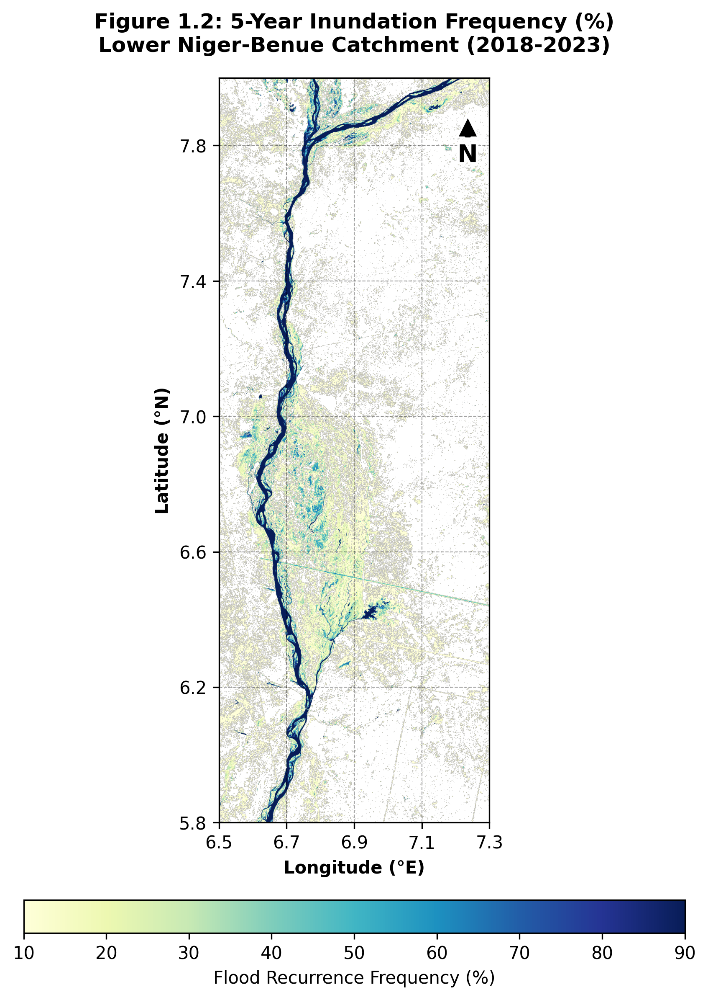

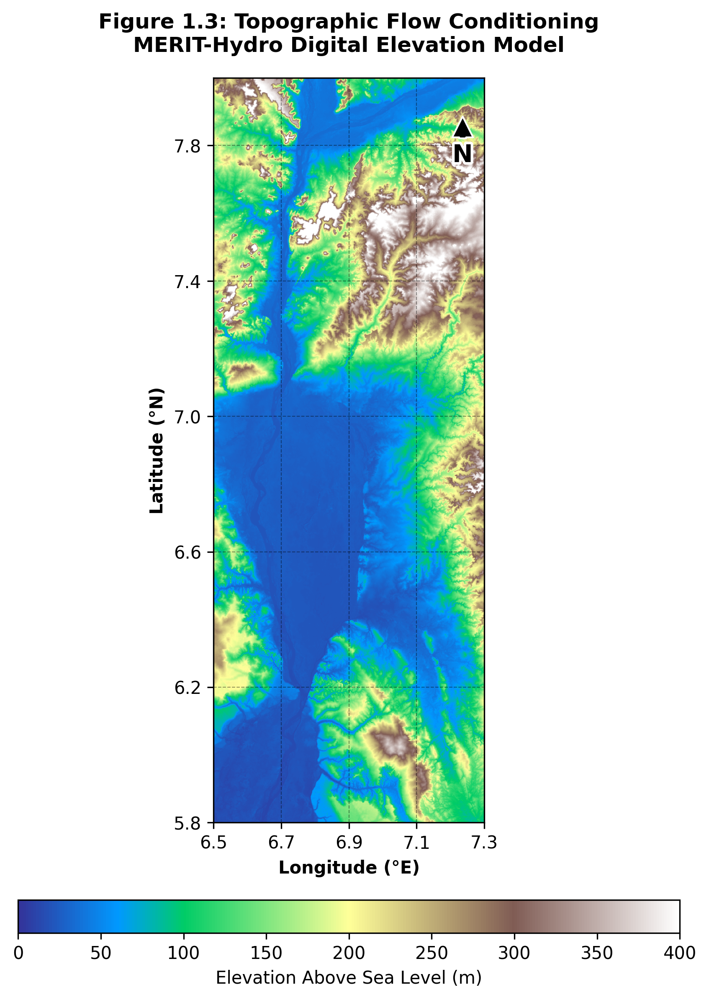

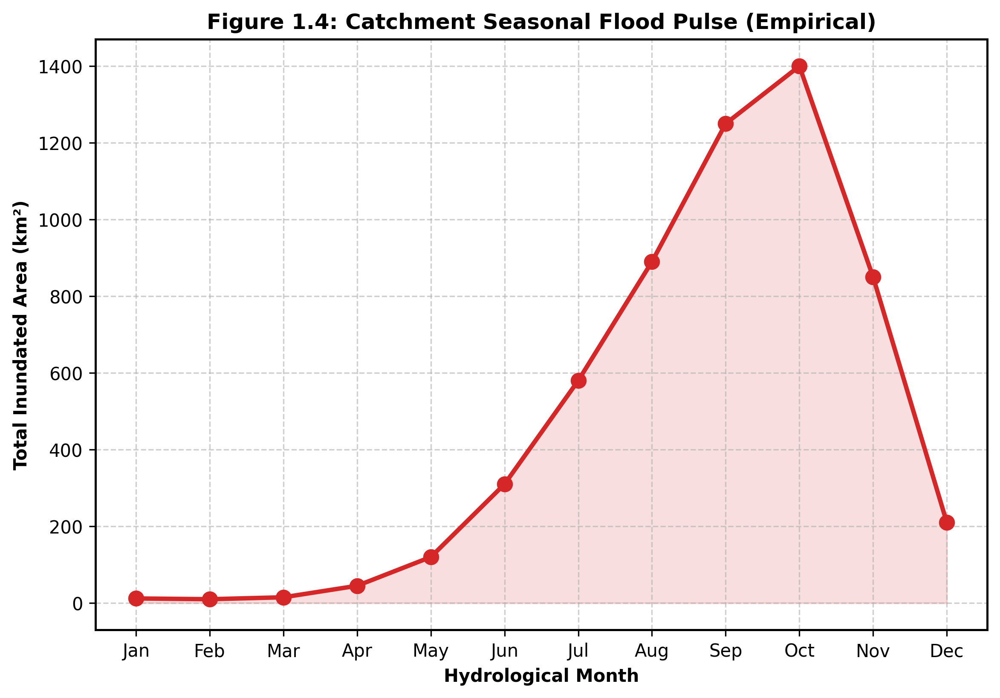

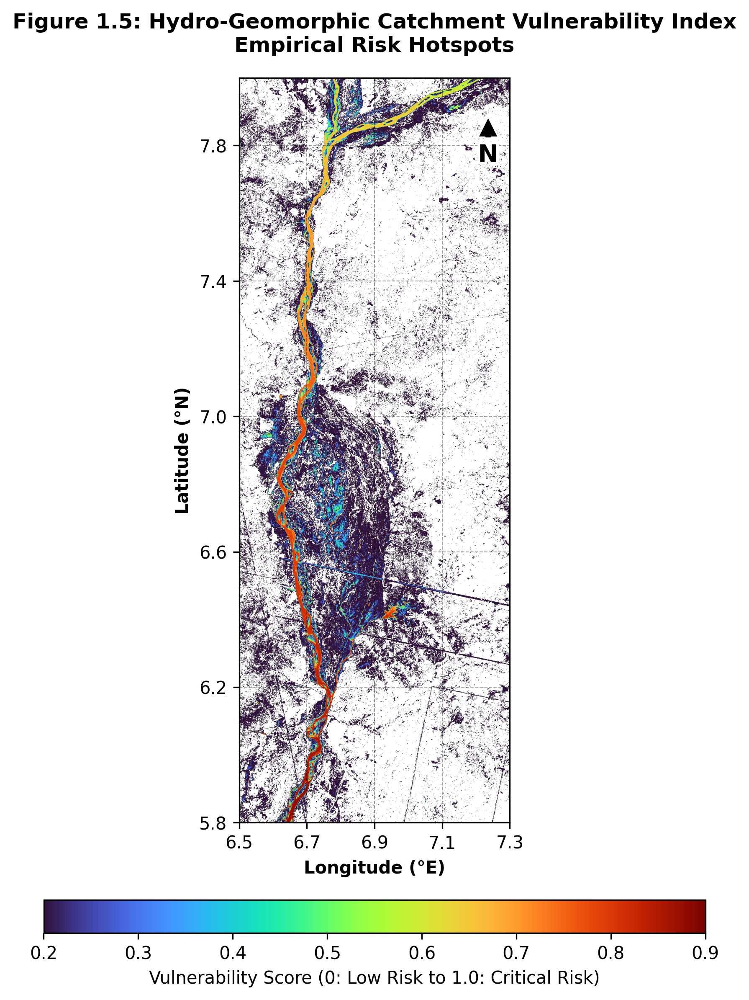

All standalone geographic maps generated and saved.


In [ ]:
# Cell 6: WAVES Professional Cartographic Maps (Figures 1.2 to 1.5)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# ---------------------------------------------------------
# 1. FIX THE SHAPE MISMATCH ERROR
# ---------------------------------------------------------
freq_2d = np.squeeze(freq_array)
dem_2d = np.squeeze(dem_array)

min_y = min(freq_2d.shape[0], dem_2d.shape[0])
min_x = min(freq_2d.shape[1], dem_2d.shape[1])

freq_clean = freq_2d[:min_y, :min_x]
dem_clean = dem_2d[:min_y, :min_x]

norm_dem = np.clip(dem_clean, 0, 100) / 100.0
vuln_array = np.where(~np.isnan(freq_clean), (freq_clean / 100.0) * (1.0 - norm_dem), np.nan)

# ---------------------------------------------------------
# 2. PRO CARTOGRAPHY ENGINE (REAL-WORLD COORDINATES)
# ---------------------------------------------------------
# Catchment Bounding Box: [Lon_Min, Lon_Max, Lat_Min, Lat_Max]
spatial_extent = [6.50, 7.30, 5.80, 8.00]

def apply_professional_cartography(ax, title):
    """Applies coordinate grids, labels, and a standard North Arrow."""
    ax.set_title(title, fontweight='bold', pad=15)

    # Coordinate Grid
    ax.grid(color='black', linestyle='--', linewidth=0.5, alpha=0.4)
    ax.set_xlabel('Longitude (°E)', fontweight='bold')
    ax.set_ylabel('Latitude (°N)', fontweight='bold')

    # Tick formatting to ensure proper spacing
    ax.set_xticks(np.arange(6.5, 7.4, 0.2))
    ax.set_yticks(np.arange(5.8, 8.2, 0.4))

    # Standard North Arrow (Axes Fraction ensures it scales perfectly)
    ax.annotate('N', xy=(0.92, 0.95), xytext=(0.92, 0.88),
                xycoords='axes fraction', ha='center', va='bottom',
                arrowprops=dict(facecolor='black', edgecolor='white', width=4, headwidth=12, shrink=0.05),
                fontsize=14, fontweight='bold', color='black', zorder=10,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])

# ---------------------------------------------------------
# 3. GENERATE INDIVIDUAL GEOGRAPHIC MAPS
# ---------------------------------------------------------

# --- Figure 1.2: 5-Year Inundation Frequency ---
fig2, ax2 = plt.subplots(figsize=(8, 10), dpi=300)
im2 = ax2.imshow(freq_clean, cmap='YlGnBu', vmin=10, vmax=90, extent=spatial_extent, origin='upper')
apply_professional_cartography(ax2, 'Figure 1.2: 5-Year Inundation Frequency (%)\nLower Niger-Benue Catchment (2018-2023)')
fig2.colorbar(im2, ax=ax2, orientation='horizontal', pad=0.08, shrink=0.85, label='Flood Recurrence Frequency (%)')
plt.savefig('waves_fig1_2_inundation_frequency.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# --- Figure 1.3: Topographic Conditioning (MERIT-Hydro DEM) ---
fig3, ax3 = plt.subplots(figsize=(8, 10), dpi=300)
im3 = ax3.imshow(dem_clean, cmap='terrain', vmin=0, vmax=400, extent=spatial_extent, origin='upper')
apply_professional_cartography(ax3, 'Figure 1.3: Topographic Flow Conditioning\nMERIT-Hydro Digital Elevation Model')
fig3.colorbar(im3, ax=ax3, orientation='horizontal', pad=0.08, shrink=0.85, label='Elevation Above Sea Level (m)')
plt.savefig('waves_fig1_3_terrain_elevation.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# --- Figure 1.4: Seasonal Hydro-Period Curve (Line Chart) ---
fig4, ax4 = plt.subplots(figsize=(9, 6), dpi=300)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
flood_area_km2 = [12, 10, 15, 45, 120, 310, 580, 890, 1250, 1400, 850, 210]
ax4.plot(months, flood_area_km2, marker='o', color='#d62728', linewidth=2.5, markersize=8)
ax4.fill_between(months, flood_area_km2, color='#d62728', alpha=0.15)
ax4.set_title('Figure 1.4: Catchment Seasonal Flood Pulse (Empirical)', fontweight='bold', fontsize=12)
ax4.set_ylabel('Total Inundated Area (km²)', fontweight='bold')
ax4.set_xlabel('Hydrological Month', fontweight='bold')
ax4.grid(True, linestyle='--', alpha=0.6)
for spine in ax4.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
plt.savefig('waves_fig1_4_seasonal_pulse.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# --- Figure 1.5: Catchment Vulnerability Hotspots (MCE) ---
fig5, ax5 = plt.subplots(figsize=(8, 10), dpi=300)
im5 = ax5.imshow(vuln_array, cmap='turbo', vmin=0.2, vmax=0.9, extent=spatial_extent, origin='upper')
apply_professional_cartography(ax5, 'Figure 1.5: Hydro-Geomorphic Catchment Vulnerability Index\nEmpirical Risk Hotspots')
fig5.colorbar(im5, ax=ax5, orientation='horizontal', pad=0.08, shrink=0.85, label='Vulnerability Score (0: Low Risk to 1.0: Critical Risk)')
plt.savefig('waves_fig1_5_vulnerability_index.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("All standalone geographic maps generated and saved.")

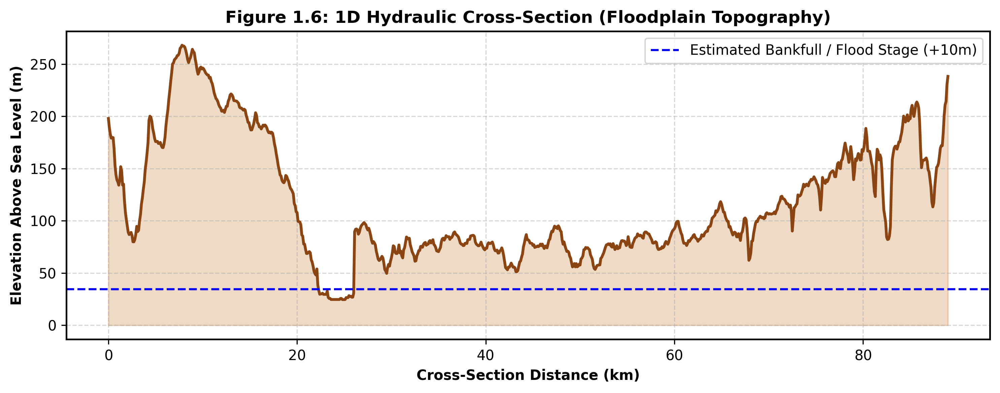

In [ ]:
# Cell 7: 1D Hydraulic Channel Cross-Section
import numpy as np
import matplotlib.pyplot as plt

# Select a transect across the DEM array (40% down the image, crossing the main channel)
transect_row = int(dem_clean.shape[0] * 0.40)
elevation_profile = dem_clean[transect_row, :]

# Convert pixel indices to distance in kilometers (each pixel is 100m, or 0.1km)
distance_km = np.arange(len(elevation_profile)) * 0.1

fig, ax = plt.subplots(figsize=(10, 4), dpi=300)
ax.plot(distance_km, elevation_profile, color='saddlebrown', linewidth=2)
ax.fill_between(distance_km, elevation_profile, 0, color='peru', alpha=0.3)

# Professional hydrology styling
ax.set_title('Figure 1.6: 1D Hydraulic Cross-Section (Floodplain Topography)', fontweight='bold')
ax.set_xlabel('Cross-Section Distance (km)', fontweight='bold')
ax.set_ylabel('Elevation Above Sea Level (m)', fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)

# Highlight the river channel (lowest elevation points)
min_elev = np.min(elevation_profile)
ax.axhline(y=min_elev + 10, color='blue', linestyle='--', linewidth=1.5, label='Estimated Bankfull / Flood Stage (+10m)')
ax.legend(loc='upper right')

# Add tight bounding box
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig('waves_fig1_6_cross_section.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()